In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df1 = pd.read_csv("insurance.csv")
df1.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [3]:
df1.info()
df1.shape

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


(1338, 7)

In [4]:
df1.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
df1.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

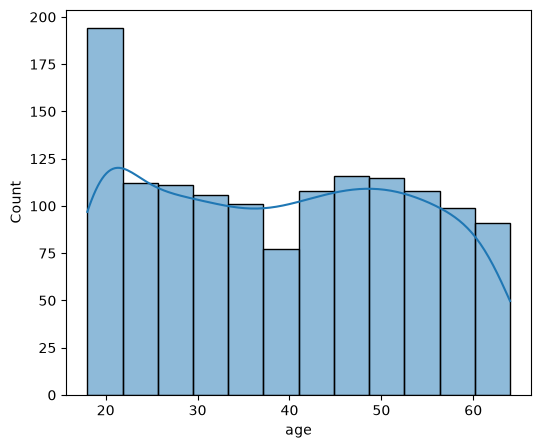

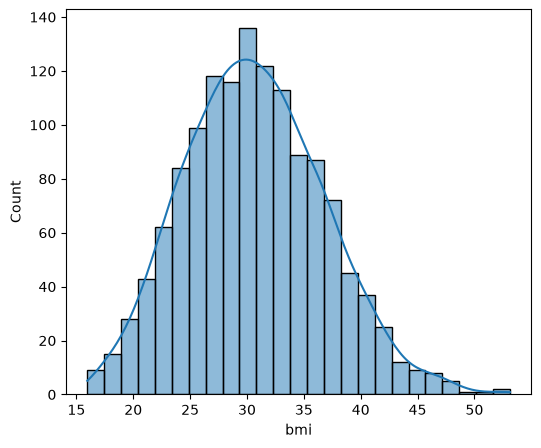

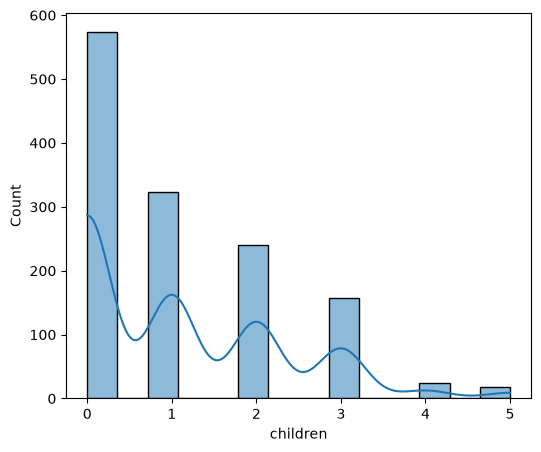

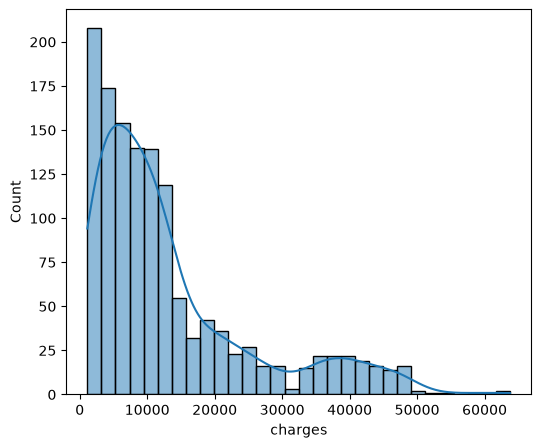

In [6]:
numeric_col = ['age' , 'bmi' , 'children' , 'charges']
for col in numeric_col:
    plt.figure(figsize= (6,5))
    sns.histplot(df1[col],kde=True)

<Axes: xlabel='sex', ylabel='count'>

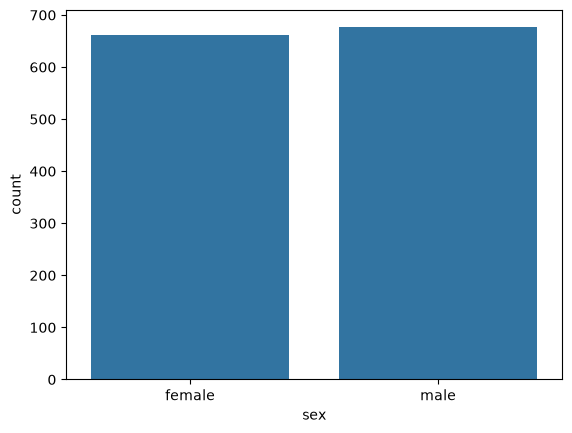

In [7]:
sns.countplot(x = df1['sex'])

<Axes: xlabel='region', ylabel='count'>

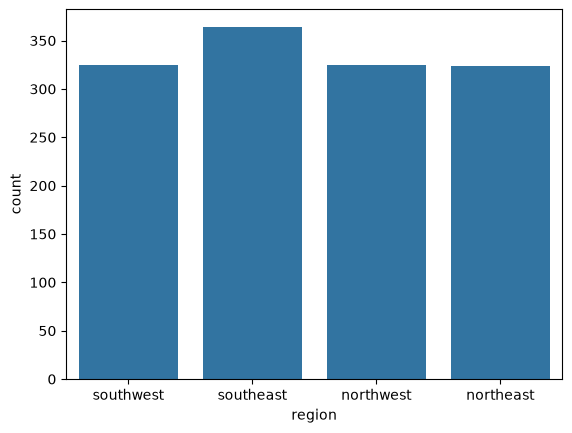

In [8]:
sns.countplot(x = df1['region'])

<Axes: xlabel='smoker', ylabel='charges'>

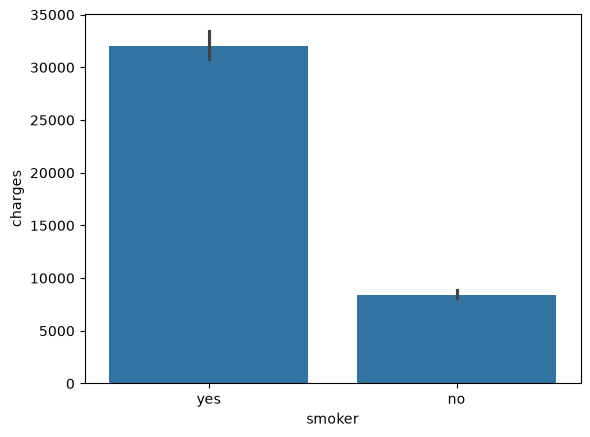

In [9]:
sns.barplot(x = 'smoker',y ='charges',data=df1)

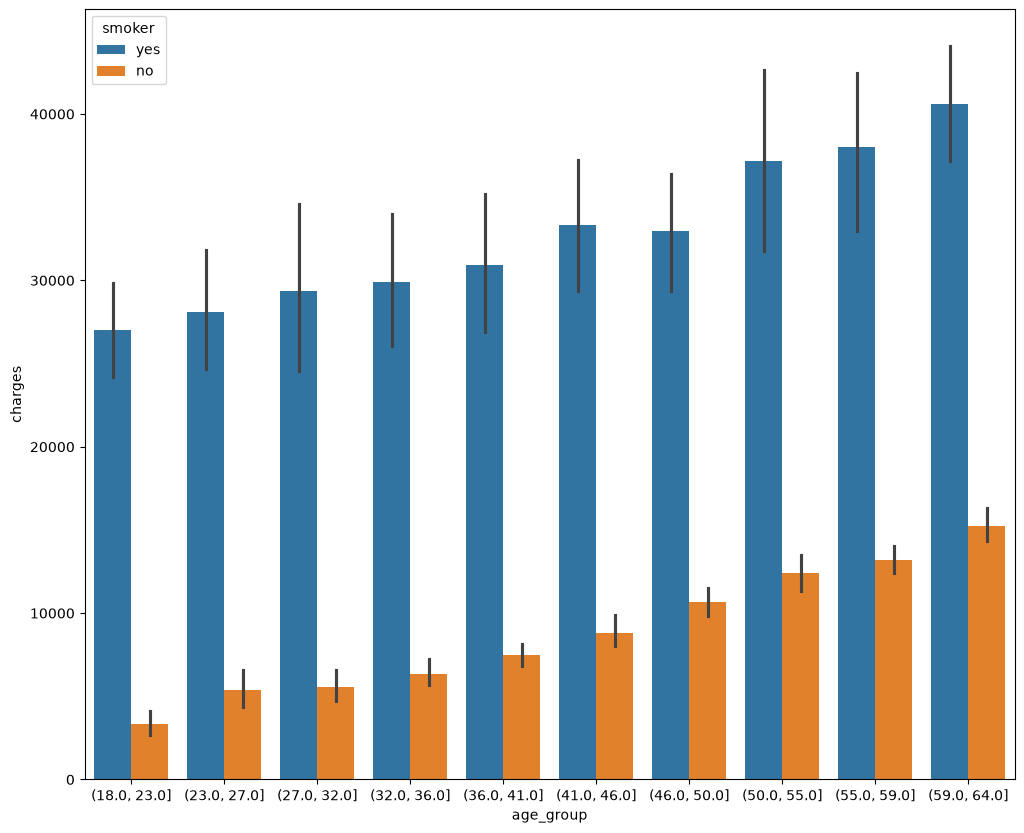

In [40]:
df1['age_group'] = pd.cut(df1['age'], bins=10,precision=0)
plt.figure(figsize=(12,10))
sns.barplot(x = 'age_group',y='charges', data=df1 ,hue='smoker')
plt.show()

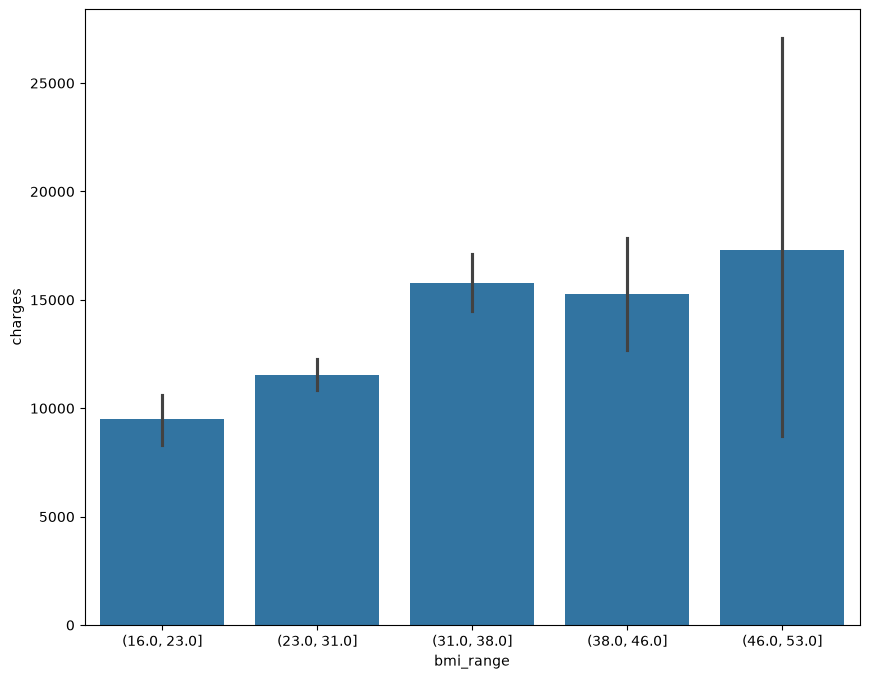

In [41]:
df1['bmi_range'] = pd.cut(df1['bmi'], bins=5,precision=0)
plt.figure(figsize=(10,8))
sns.barplot(data=df1, x='bmi_range', y='charges')
plt.show()

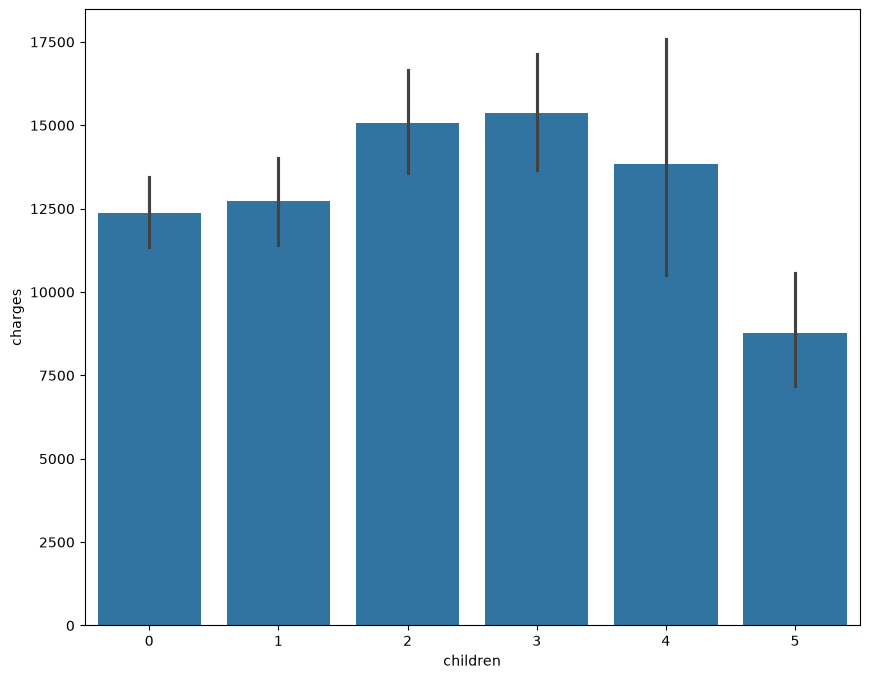

In [42]:
df1['age_group'] = pd.cut(df1['age'], bins=10,precision=0)
plt.figure(figsize=(10,8))
sns.barplot(x = 'children',y = 'charges' ,data=df1 )
plt.show()

# Data cleaning and preprocessing

In [13]:
df_cleaned = df1.copy()

In [14]:
df_cleaned.drop_duplicates(inplace=True)

In [15]:
df_cleaned['sex'] = df_cleaned['sex'].map({'male' : 0 , 'female' : 1},inplace = True)

In [16]:
df_cleaned['smoker'] = df_cleaned['smoker'].map({'no' : 0 , 'yes' : 1},inplace = True)

In [17]:
df_cleaned.rename(columns={
    'sex' : 'is_female',
    'smoker' : "is_smoker"
},inplace=True)

In [18]:
df_cleaned.drop(columns='bmi_range',inplace=True)

In [19]:
df_cleaned.drop(columns='age_group',inplace=True)

In [20]:
df_cleaned = pd.get_dummies(df_cleaned,columns=['region'])

In [21]:
df_cleaned = df_cleaned.astype(int)

In [22]:
df_cleaned['bmi_category'] = pd.cut(
    df_cleaned['bmi'],
    bins = [0, 18.5, 25, 30, 35, 40, float('inf')],
    labels = [
    'Underweight',
    'Normal',
    'Overweight',
    'Obese Class 1',
    'Obese Class 2',
    'Obese Class 3']
)


In [23]:
df_cleaned = pd.get_dummies(df_cleaned,columns=['bmi_category'])

In [24]:
df_cleaned = df_cleaned.astype(int)

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_cleaned[['age', 'bmi', 'children']] = scaler.fit_transform(
    df_cleaned[['age', 'bmi', 'children']]
)

In [26]:
from scipy.stats import pearsonr

# All features
selected_features = [
    'age', 'is_female', 'bmi', 'children', 'is_smoker',
    'region_northeast', 'region_northwest', 'region_southeast',
    'region_southwest', 'bmi_category_Underweight',
    'bmi_category_Normal', 'bmi_category_Overweight',
    'bmi_category_Obese Class 1', 'bmi_category_Obese Class 2',
    'bmi_category_Obese Class 3'
]

# Calculate Pearson correlations with charges
correlations = {
    feature: pearsonr(df_cleaned[feature], df_cleaned['charges'])[0]
    for feature in selected_features
}

# Create and sort DataFrame
correlation_df = pd.DataFrame(
    list(correlations.items()),
    columns=['Feature', 'Pearson Correlation']
)

correlation_df.sort_values(
    by='Pearson Correlation',
    ascending=False
)

,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
2,bmi,0.196236
13,bmi_category_Obese Class 2,0.118872
12,bmi_category_Obese Class 1,0.082859
14,bmi_category_Obese Class 3,0.073783
7,region_southeast,0.073577
3,children,0.067390
5,region_northeast,0.005946
6,region_northwest,-0.038695


In [27]:
from scipy.stats import chi2_contingency

# Categorical and one-hot encoded features
cat_features = [
    'is_female', 'is_smoker',
    'region_northeast', 'region_northwest',
    'region_southeast', 'region_southwest',
    'bmi_category_Underweight', 'bmi_category_Normal',
    'bmi_category_Overweight', 'bmi_category_Obese Class 1',
    'bmi_category_Obese Class 2', 'bmi_category_Obese Class 3'
]

alpha = 0.05

# Divide charges into 4 bins
df_cleaned['charges_bin'] = pd.qcut(
    df_cleaned['charges'],
    q=4,
    labels=False,
    duplicates='drop'
)

chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(
        df_cleaned[col],
        df_cleaned['charges_bin']
    )

    chi2_stat, p_val, _, _ = chi2_contingency(contingency)

    decision = (
        'Reject Null (Keep Feature)'
        if p_val < alpha
        else 'Accept Null (Drop Feature)'
    )

    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')

chi2_df

,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
is_female,10.258784,0.01649,Reject Null (Keep Feature)
bmi_category_Obese Class 2,7.773364,0.050935,Accept Null (Drop Feature)
region_northeast,6.438442,0.092122,Accept Null (Drop Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_category_Normal,4.771699,0.189298,Accept Null (Drop Feature)
bmi_category_Overweight,4.450807,0.21672,Accept Null (Drop Feature)
bmi_category_Underweight,3.37403,0.337471,Accept Null (Drop Feature)
bmi_category_Obese Class 1,1.238129,0.743875,Accept Null (Drop Feature)


In [28]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese Class 1,bmi_category_Obese Class 2,bmi_category_Obese Class 3,charges_bin
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,0,0,1,0,0,0,3
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,0,0,0,1,0,0,0
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,0,0,0,1,0,0,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,0,1,0,0,0,0,3
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1,0,0,0,0,1,0,0,0,2
1334,-1.511647,1,0.135659,-0.909234,0,2205,1,0,0,0,0,0,0,1,0,0,0
1335,-1.511647,1,0.952670,-0.909234,0,1629,0,0,1,0,0,0,0,0,1,0,0
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0,0,1,0,1,0,0,0,0,0


In [29]:
final_df = df_cleaned[['age' , 'is_female', 'bmi' , 'children' , 'is_smoker', 'charges' , 'region_northeast','region_northwest','region_southeast','region_southwest' , 'bmi_category_Obese Class 2']]

In [33]:
final_df.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Obese Class 2
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,0
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,0


In [30]:
from sklearn.model_selection import train_test_split


In [31]:
X = final_df.drop(columns='charges')
y = final_df['charges']

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

In [33]:
from sklearn.linear_model import LinearRegression

In [34]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[3477.53, 91.58,1854.58,...,-376. ,-196.44, 501.26]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['age','is_female','bmi',...,'region_southeast','region_southwest', 'bmi_category_Obese Class 2']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8355
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [ ]:
y_pred = model.predict(X_test)

In [36]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test,y_pred)

In [38]:
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

In [46]:
print("R2:", r2)
print("Adjusted R2:", adjusted_r2)

R2: 0.8062733382438022
Adjusted R2: 0.7987353358408373
